# Assignment 7: Expectation Maximization

MIDS W281: Computer Vision

## Recommended Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2
from skimage.color import rgb2gray
import skimage.feature
from matplotlib.patches import Circle

![Hybrid Teaser](https://raw.githubusercontent.com/W281/fileRepository/main/Assignments/output.gif)

 ### Overview
In tasks with noisy input data, it is often necessary to estimate parameters using an iterative approach. To illustrate this, we have provided you a realistic (but very simple) optimization problem. 

You are tasked with writing the software for a parts inspection system. The input to this system is a color image of a circular part. Your task is to locate and fit a circle (center and radius) to the part, and then determine whether the size of the part (its radius) is within a specified tolerance. You will use the expectation/maximization (EM) algorithm to simultaneously locate the boundary of the circular part, fit a circle to the part, and estimate the goodness of the fit.

### Description

1. To begin, your system should load a color (RGB) image, convert the image to grayscale, and extract the salient edges in the image. You can use the Canny edge detector from Python's OpenCV library to find the edges. This function will return a binary image with a value of 1 at a pixel location corresponding to a salient edge and 0 otherwise. Note that you will need to play around with the size of the filter to get a useful output. You might need to exclude the edges of the image and then extract the x- and y-coordinates of all pixels with an edge value equal to 1 (see numpy's `argwhere`). It is from these coordinates that we will find and fit a circle.  

2. The coordinates of each edge pixel correspond to one of two models:   
    (1) a circle with center $(c_x,c_y)$ and radius $(r)$; or  
    (2) an "outlier" model.  
    The conditional probability of belonging to model 1 will be modeled as a Gaussian distribution $(g(d) = exp(-d^2/σ)$ and will depend on the distance, $d$, of each point to the circle. The conditional probability of belonging to model 2 will be modeled as a uniform distribution and fixed to be 1/10.  
    **HINT: the async mentioned two kinds of conditional probabilities, figure out which kind of conditional probability was just provided for models 1 and 2, and how this kind of conditional probability is used throughout the entire EM process**

3. You should begin your EM iterations by initializing $(c_x,c_y)$ to be the image center, $r=190$ pixels, and $σ=128$.   

4. In the E-step, the residual error for model 1 is based on the shortest distance, $d$, between a point $(x,y)$ and the current estimate of the circle with center $(c_x,c_y)$ and radius, $r$. This distance is:  
    $$d=\left\lvert \sqrt{ (x-c_x)^2 + (y-c_y)^2} - r \right\rvert$$
    
5. In the M-step, you will use weighted total least-squares to re-estimate the paramters of the circle. First, implement the total least-squares estimator described in Section 2 of the gander_golub_strebel.pdf paper in the Assignment 7 GitHub repo. The weights of weighted total least-squares estimator are computed in the E-step. Incorporate this weighting into your total least-squares estimator and **solve using SVD.** 

6. After performing the E- and M-step, update the value of $σ$.  
    **HINT: when updating sigma, you can assume untied covariance and that the residuals for the noise model (model 2) is 0, but you should still be able to calculate the conditional probability that was not given above for model 2 if you understand the concepts**

7. Repeatedly perform the E- and M-steps until the difference between subsequent estimates of the circle center and radius are each less than 0.1 pixels.  

8. As shown in the sample output above, on each EM iteration you should display two images:  
    (1) the current circle superimposed on top of the original RGB image;  
    (2) the current probability of each pixel location belonging to model 1 visualized as an image. 
    
9. Show your final fitting results on the five images provided in the "discs" directory.  
**If your solution is similar to ours, it might fail on the image disc4.jpg. If so, fix this failure by choosing a better initial value for $(c_x, c_y)$.**   

### Deliverables:

- Python code to perform the above EM algorithm.  
- Plots showing the steps for for EM for each of the image.  
- Plot showing the final fitting results, i.e. the circle super-imposed on the RGB disc image.

To see a sample output of the convergence process, see images/SampleOutput.mov.  Your convegence process does not need to match it exactly, but it should be similar.

### Create your Function to execute the above steps

In [2]:
def find_EM(fileName):
    # Load the image, convert to grayscale, and keep the edge pixels that
    # belong either to the circular part or to an outlier process.
    rgb_im = plt.imread(fileName)
    im = rgb2gray(rgb_im)

    # Raise the Canny scale until the edge set is under 10k points.
    # A 10-pixel border is dropped so the image rectangle is not an edge.
    edgeIm = None
    for canny_sigma in (2.0, 3.0, 4.0, 5.0):
        edgeIm = skimage.feature.canny(im, sigma=canny_sigma)
        border = 10
        edgeIm[:border, :] = False
        edgeIm[-border:, :] = False
        edgeIm[:, :border] = False
        edgeIm[:, -border:] = False
        if int(edgeIm.sum()) < 10000:
            break

    # argwhere returns (row, col) = (y, x)
    cord = np.argwhere(edgeIm)
    Y = cord[:, 0].astype(np.float64)
    X = cord[:, 1].astype(np.float64)
    noOfPoints = cord.shape[0]
    print(f"Number of Points: {noOfPoints}")

    plt.imshow(im, cmap="gray")
    plt.plot(X, Y, "r.", markersize=1)
    plt.title("Edge coordinates")
    plt.show()

    # Image center, radius 190, sigma 128, as specified.
    # disc4 sits low in the frame, so the image center misses the outer
    # rim and the fit walks into the noise. Start that image at the
    # centroid of the edge pixels instead.
    new_cx = im.shape[1] / 2.0
    new_cy = im.shape[0] / 2.0
    if os.path.basename(fileName).startswith("disc4"):
        new_cx = float(np.mean(X))
        new_cy = float(np.mean(Y))
    new_r = 190.0

    prev_cx = 0.0
    prev_cy = 0.0
    prev_r = 0.0
    sigma = 128.0

    iteration = 0
    while (
        (np.abs(prev_cx - new_cx) > 0.1)
        or (np.abs(prev_cy - new_cy) > 0.1)
        or (np.abs(prev_r - new_r) > 0.1)
    ):
        if iteration > 40:
            break
        iteration += 1

        prev_cx = new_cx
        prev_cy = new_cy
        prev_r = new_r

        # E-step. Model 1 is a Gaussian of the distance to the circle,
        # g(d) = exp(-d^2 / sigma). Model 2 is uniform with density 1/10.
        # These are p(point | model). The weight below is the posterior
        # p(model 1 | point), with equal model priors.
        d = np.abs(np.sqrt((X - prev_cx) ** 2 + (Y - prev_cy) ** 2) - prev_r)
        inlier = np.exp(-np.clip(d ** 2 / sigma, None, 60.0))
        expectation = inlier / (inlier + 0.1)

        exIm = np.zeros(im.shape[:2], dtype=np.float64)
        exIm[cord[:, 0], cord[:, 1]] = expectation

        fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))
        ax[0].imshow(rgb_im)
        circ = Circle((prev_cx, prev_cy), radius=prev_r, fill=False, color="cyan", linewidth=2)
        ax[0].add_patch(circ)
        ax[1].imshow(exIm, cmap="hot")
        ax[0].set_title(
            f"r = {np.around(prev_r, 2)}, cx = {np.around(prev_cx, 2)}, cy = {np.around(prev_cy, 2)}"
        )
        ax[1].set_title("P(model 1 | edge)")
        plt.show()

        # M-step. Algebraic circle from Gander, Golub, and Strebel, Section 2:
        # a(x^2 + y^2) + b x + c y + f = 0, solved by the smallest right
        # singular vector of the weighted design matrix. sqrt(weight) makes
        # ||W B u||^2 equal the weighted sum of squared algebraic residuals.
        design = np.column_stack([X ** 2 + Y ** 2, X, Y, np.ones(noOfPoints)])
        weighted = design * np.sqrt(expectation)[:, None]
        _, _, vt = np.linalg.svd(weighted, full_matrices=False)
        coeff_a, coeff_b, coeff_c, coeff_f = vt[-1]
        new_cx = -coeff_b / (2.0 * coeff_a)
        new_cy = -coeff_c / (2.0 * coeff_a)
        new_r = np.sqrt(new_cx ** 2 + new_cy ** 2 - coeff_f / coeff_a)

        # Untied inlier variance. Model 2 has residual 0 and its own
        # covariance, so it does not enter this update.
        sigma = np.sum(expectation * d ** 2) / np.sum(expectation)

    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(rgb_im)
    ax.add_patch(Circle((new_cx, new_cy), radius=new_r, fill=False, color="cyan", linewidth=2))
    ax.set_title(
        f"final  r = {np.around(new_r, 2)}, cx = {np.around(new_cx, 2)}, cy = {np.around(new_cy, 2)}"
    )
    ax.set_axis_off()
    plt.show()
    print(
        f"Final fit: r = {new_r:.2f}, cx = {new_cx:.2f}, cy = {new_cy:.2f}, sigma = {sigma:.3f}"
    )


### Run your function for all disc images

Image: disc2.jpg
Number of Points: 2567


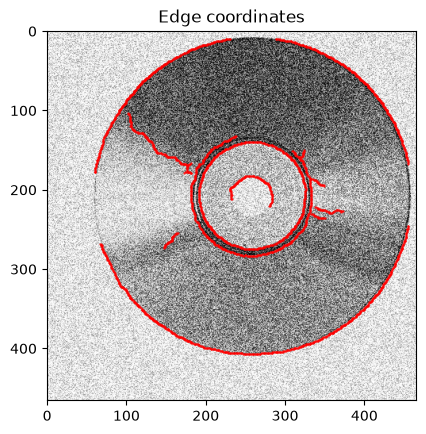

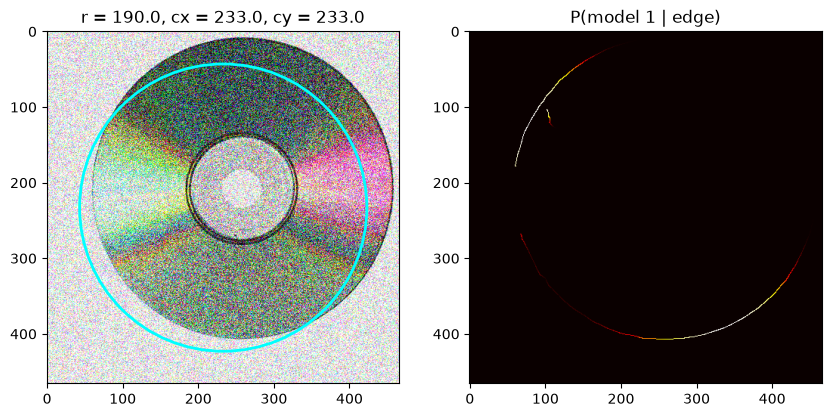

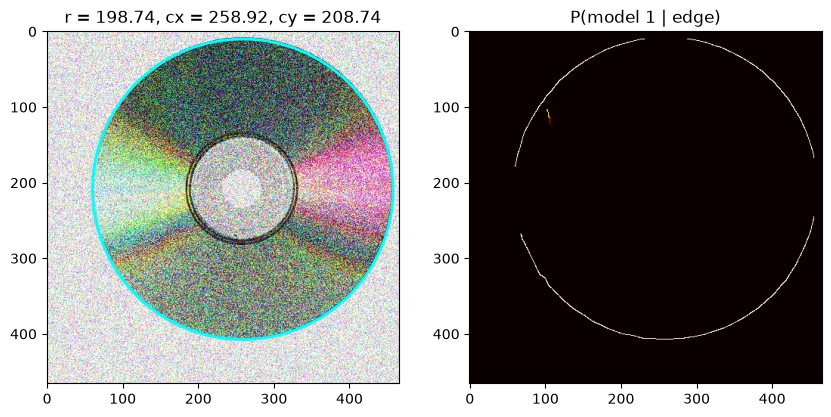

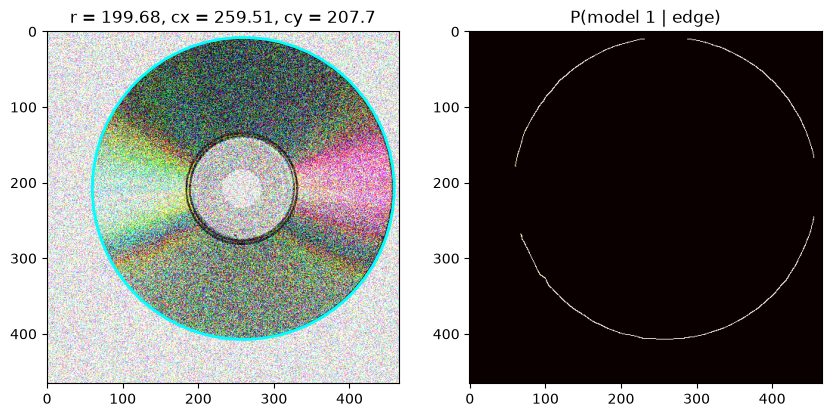

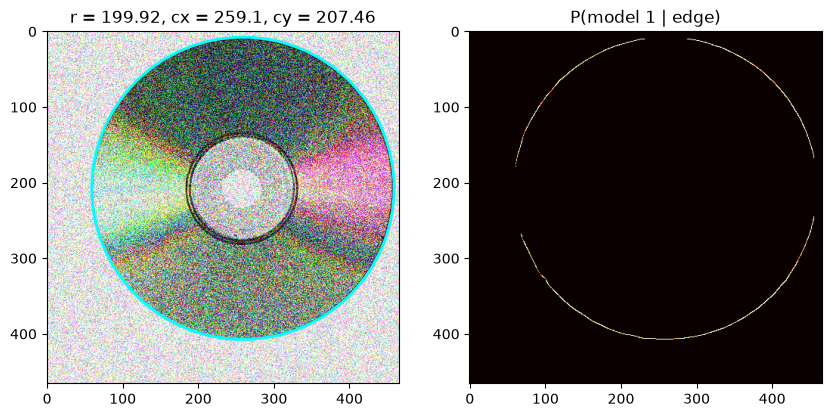

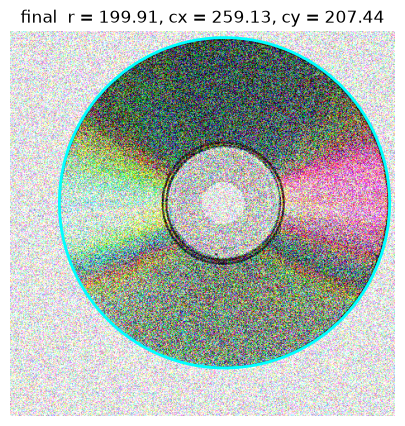

Final fit: r = 199.91, cx = 259.13, cy = 207.44, sigma = 0.262
Image: disc3.jpg
Number of Points: 2214


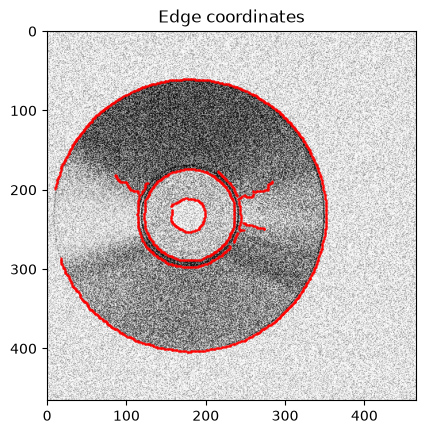

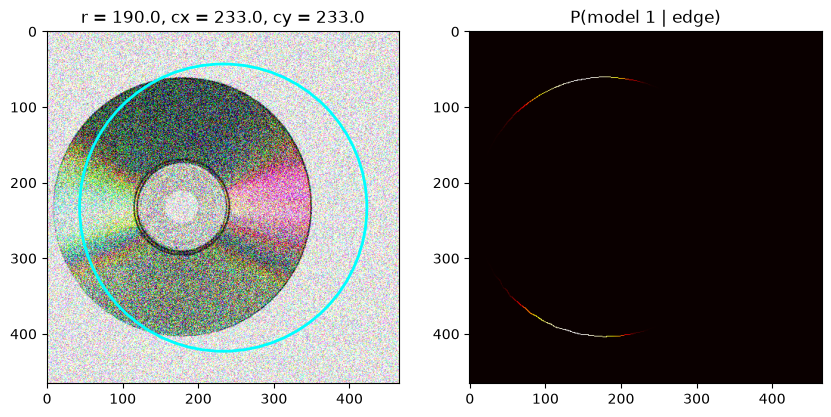

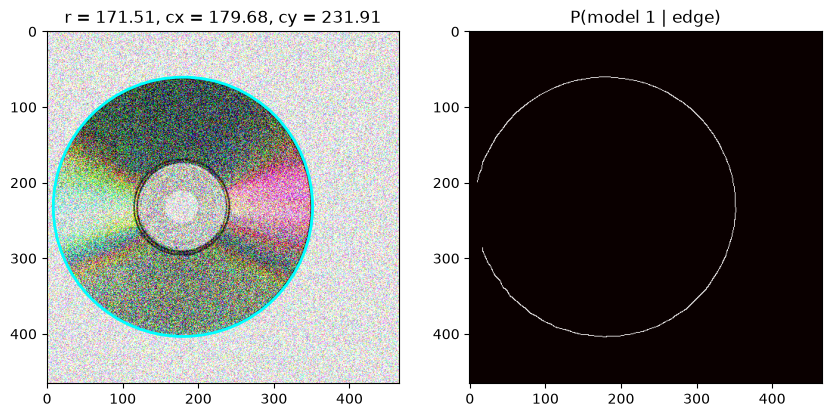

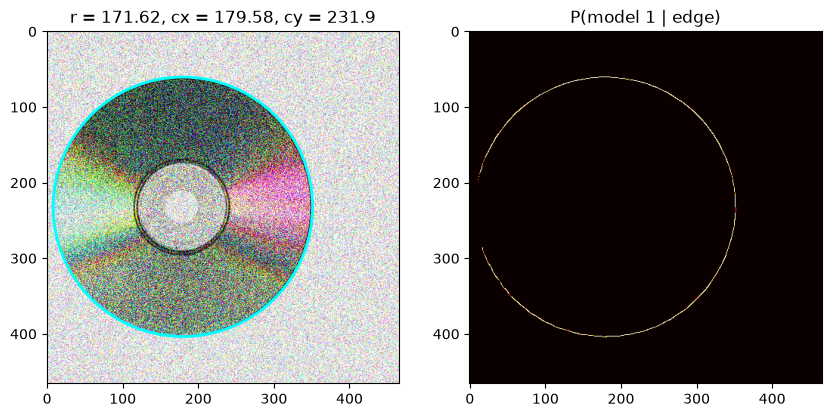

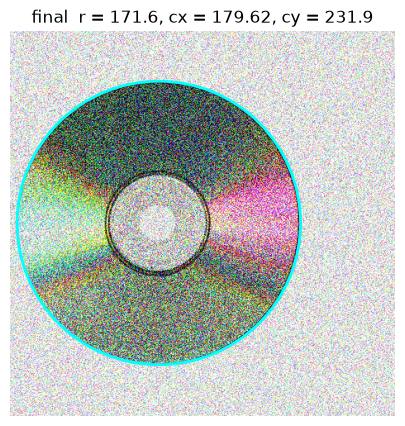

Final fit: r = 171.60, cx = 179.62, cy = 231.90, sigma = 0.157
Image: disc1.jpg
Number of Points: 2902


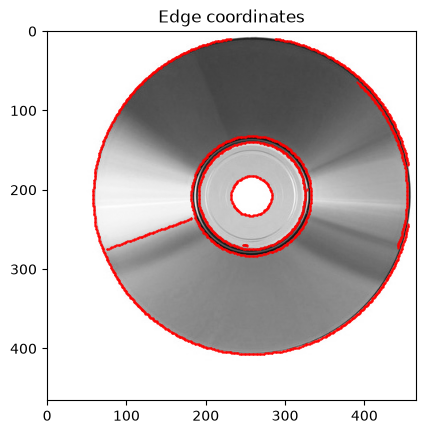

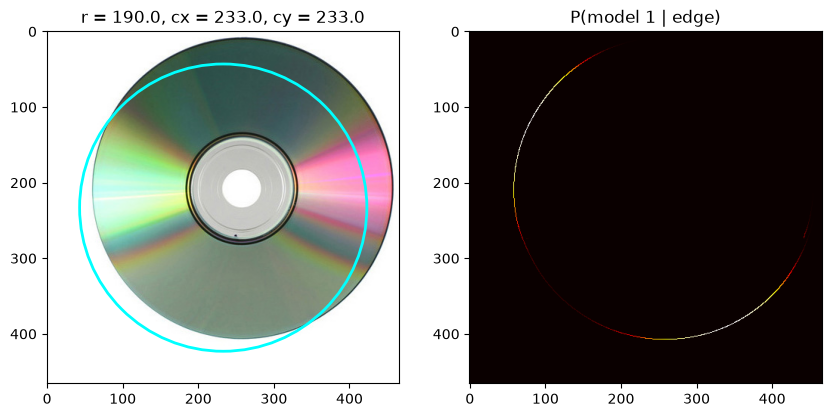

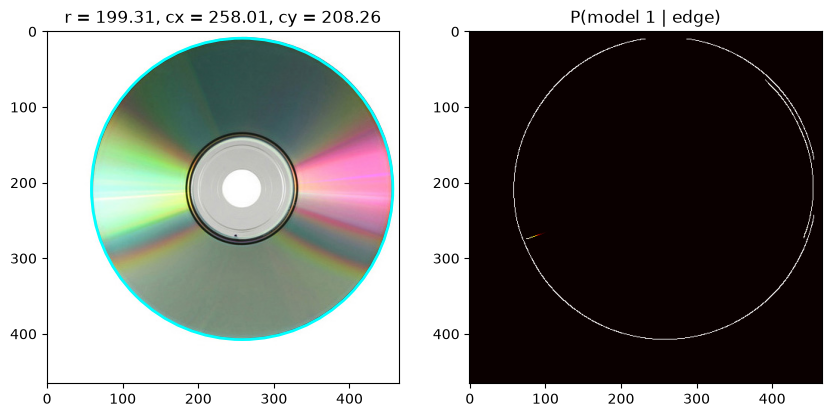

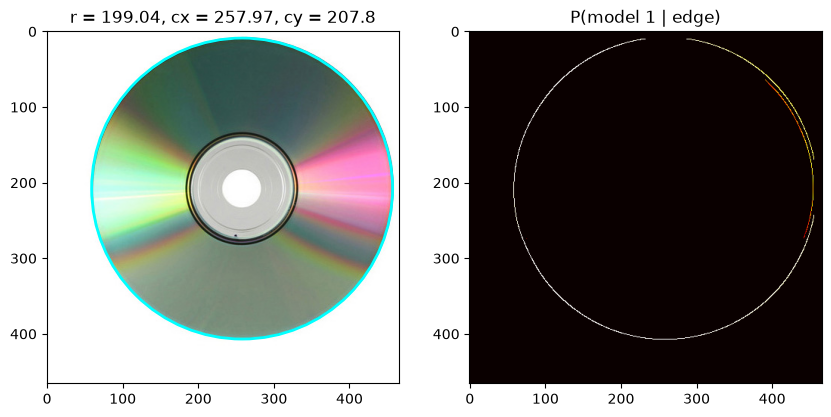

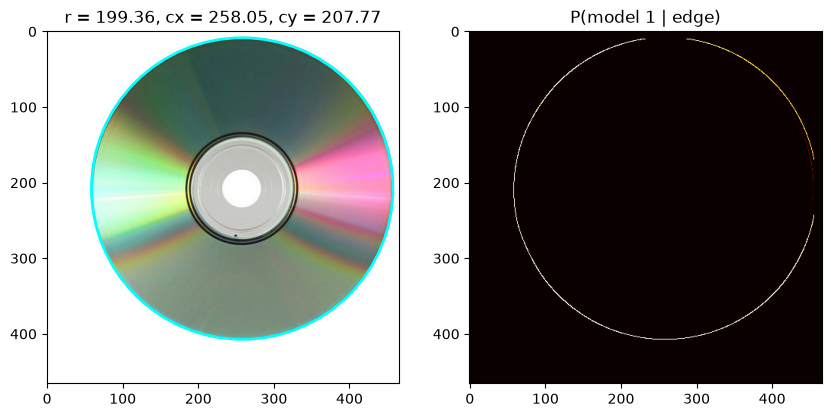

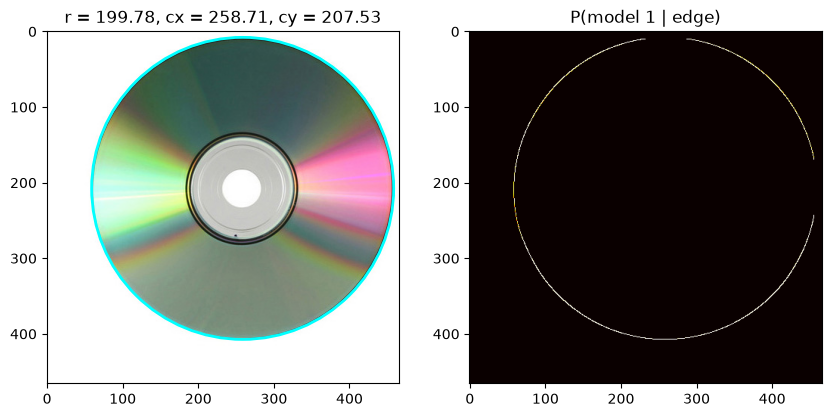

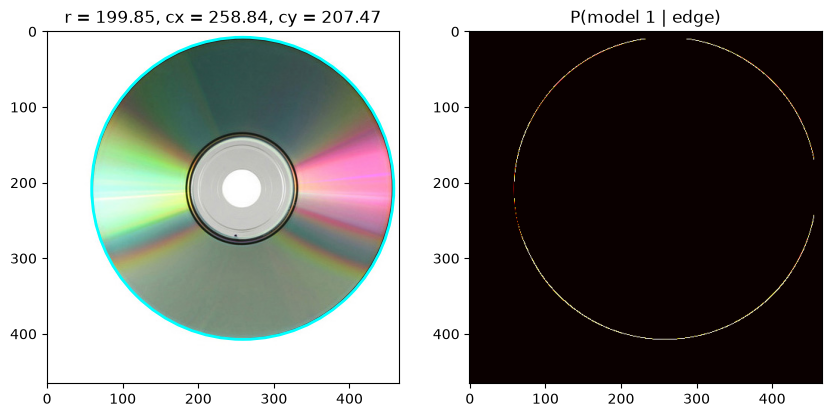

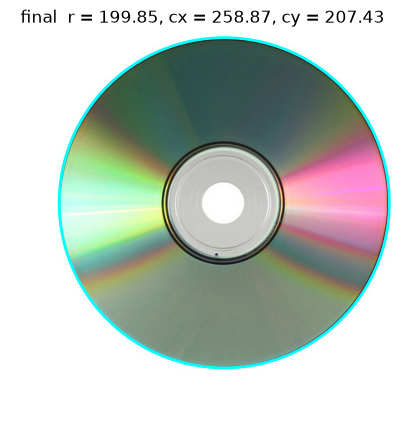

Final fit: r = 199.85, cx = 258.87, cy = 207.43, sigma = 0.162
Image: disc4.jpg
Number of Points: 1822


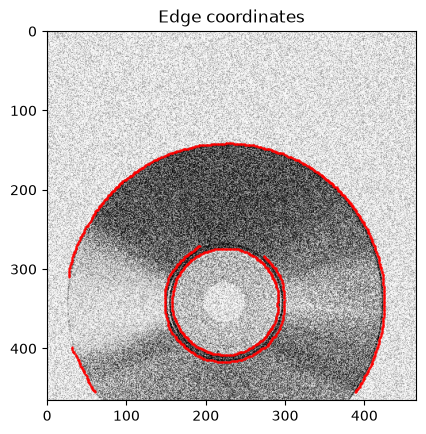

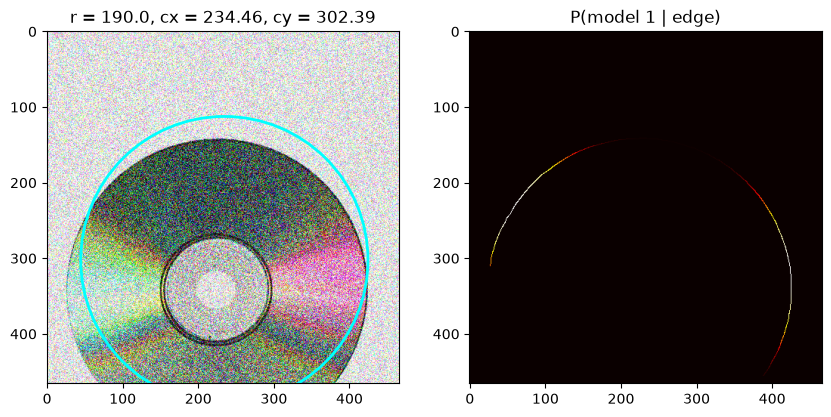

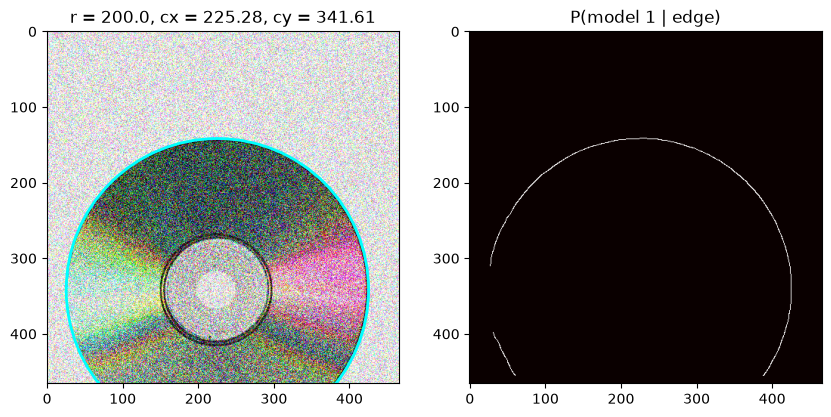

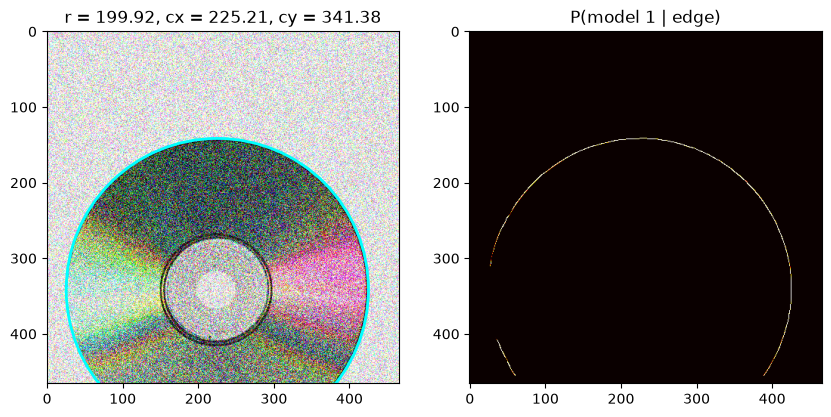

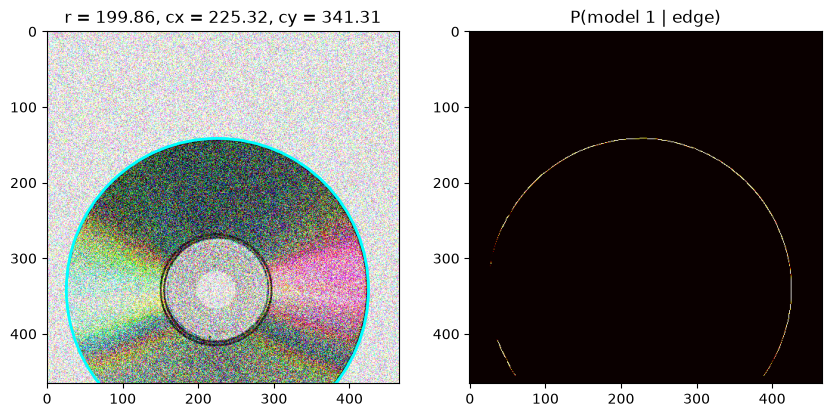

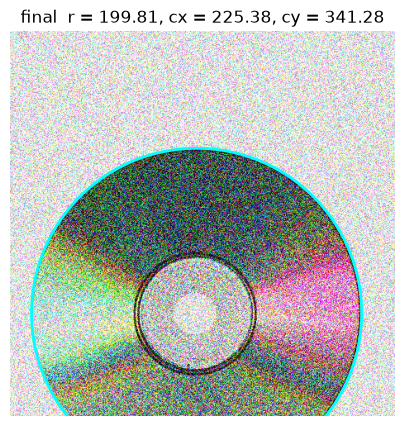

Final fit: r = 199.81, cx = 225.38, cy = 341.28, sigma = 0.147
Image: disc5.jpg
Number of Points: 3226


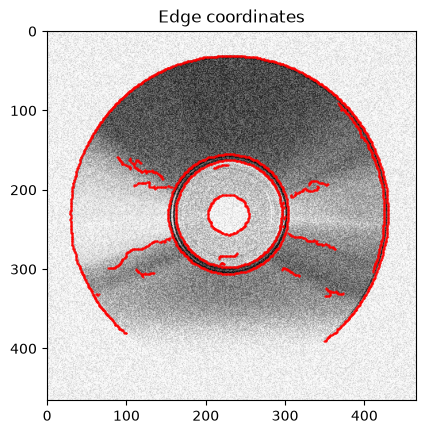

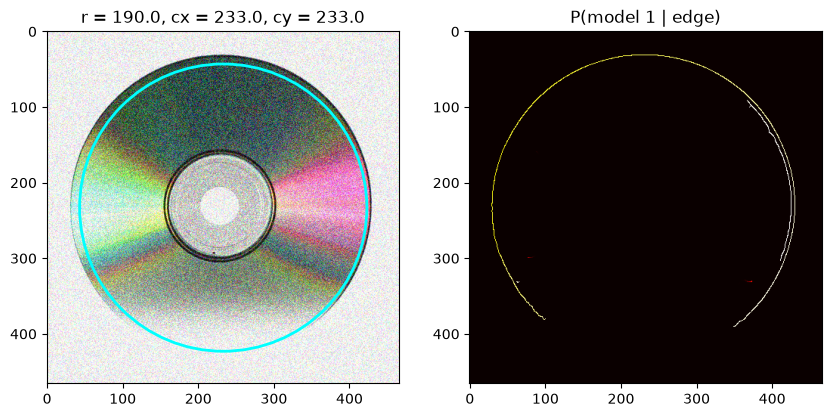

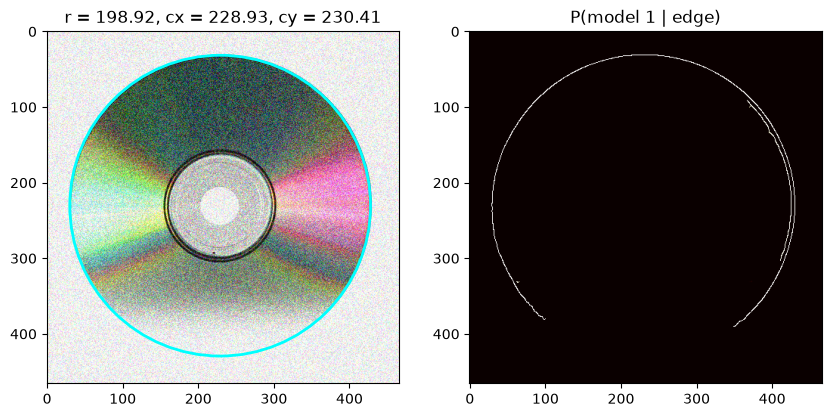

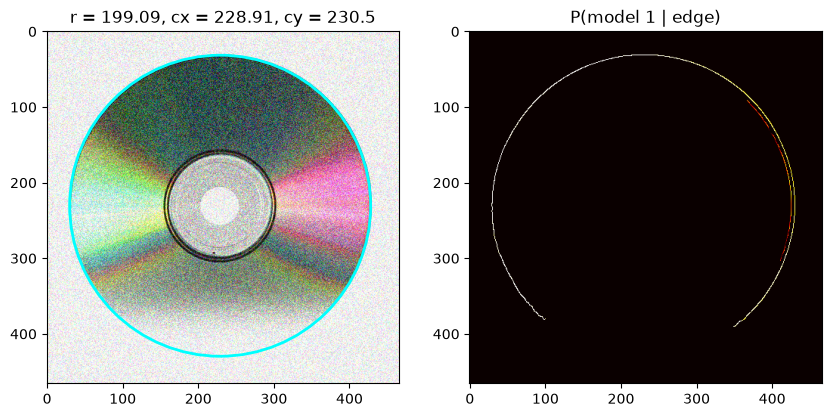

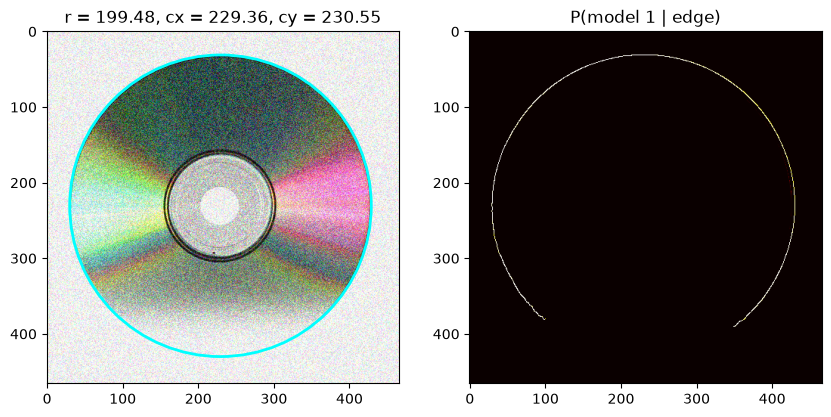

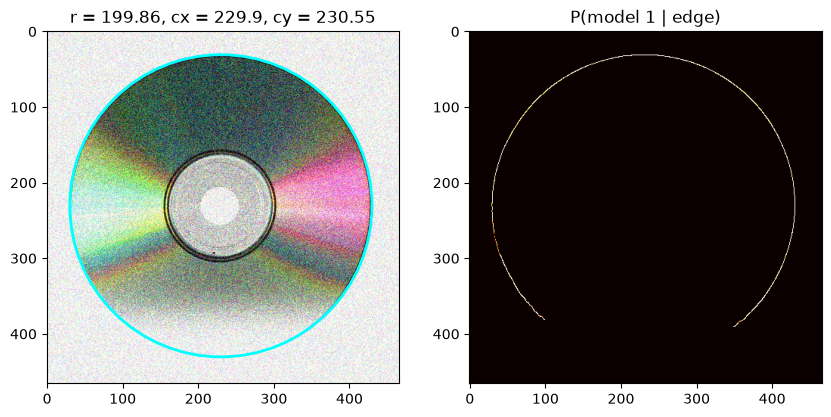

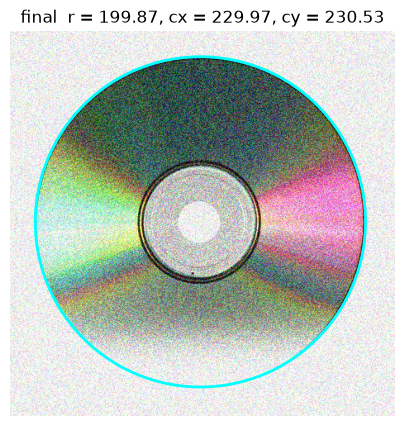

Final fit: r = 199.87, cx = 229.97, cy = 230.53, sigma = 0.275


In [3]:
for image in os.listdir('discs'):
    print(f'Image: {image}')
    find_EM('discs/' + image)